# ColorMNIST: Design and Properties

Reference notebook for the ColorMNIST design used in the counterfactual image-sampling experiments.
It documents the generating mechanism, the confounding channel, the colour law of the observed and
interventional distributions, and the overlap conditions that govern estimation difficulty. No
estimator is fitted here.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")

from causality_utils import effective_sample_size
from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed)
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 1. Design

ColorMNIST design of Dance et al. (2026, Appendix B.2.4):

$$
X \sim U[0, 1], \qquad
A \mid x \sim \mathrm{Bernoulli}\big(e(x)\big), \quad e(x) = \sigma\big(w (x - \tfrac12)\big),
$$

$$
Y \mid x, a \;=\; M \odot \big(c_{\mathrm{fg}}(x)\, S_a\big), \qquad
c_{\mathrm{fg}}(x) = (x, \alpha, 1 - x),
$$

where $S_a$ is a random grayscale MNIST digit of class $d_a$, $M$ a soft foreground mask, and the
background is black. Configuration used throughout: $(d_0, d_1) = (1, 6)$, $w = 10$,
$(\tau, k) = (0.08, 20)$, $\alpha = 0.2$.

Two structural facts distinguish this design from the DecFM 2D mixture:

- the confounder acts on the outcome **directly** (through the colour) *and* through the treatment
  (which selects the digit class), so each observed arm has a tilted colour law;
- the two interventional laws $P(Y(0)) \neq P(Y(1))$ (different digit classes), but both share the
  **uniform** colour law, since intervening breaks the $X$–$A$ dependence.

The pixel ratio $R/(R+B)$ recovers $X$ exactly on the black background, giving a free scalar
diagnostic of the colour law.

n = 20000   P(A=1) = 0.496   E[X | A=0] = 0.279   E[X | A=1] = 0.721


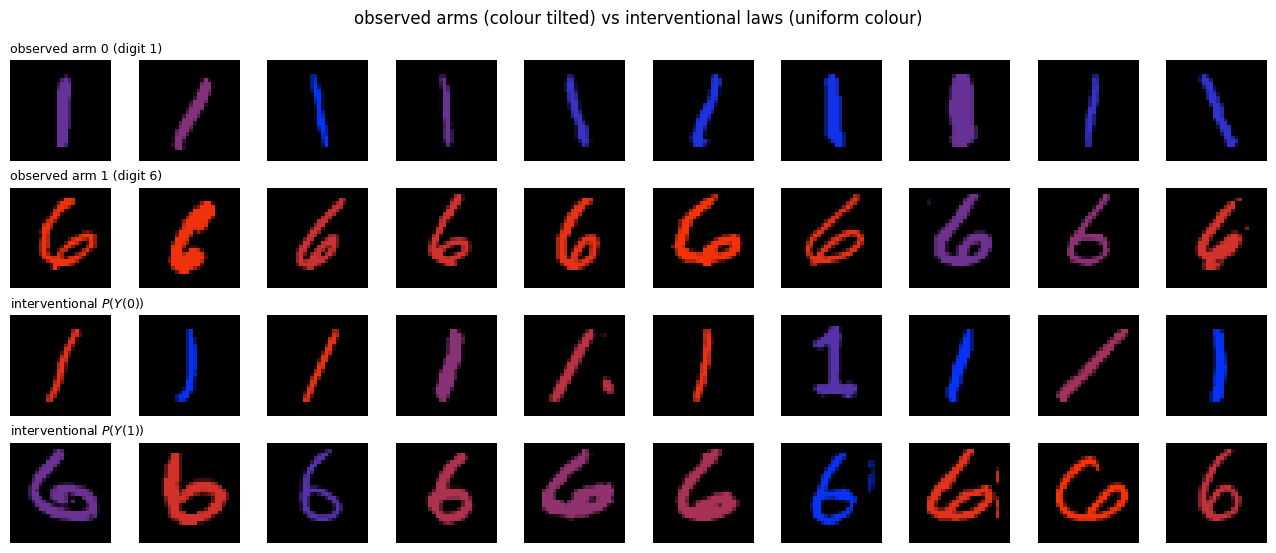

In [2]:
n = 20000
W_CONF, TAU = 10.0, 0.08
pools = load_digit_pools(root="../../data", device=device)
generator = torch.Generator(device=device).manual_seed(SEED)
X, A, Y = sample_observed(pools, n, w_conf=W_CONF, tau=TAU, generator=generator)
_, Y0 = sample_interventional(pools, 4000, a=0, tau=TAU,
                              generator=torch.Generator(device=device).manual_seed(SEED + 1))
_, Y1 = sample_interventional(pools, 4000, a=1, tau=TAU,
                              generator=torch.Generator(device=device).manual_seed(SEED + 2))
propensity = torch.sigmoid(W_CONF * (X - 0.5))
print(f"n = {n}   P(A=1) = {A.float().mean():.3f}   "
      f"E[X | A=0] = {X[A == 0].mean():.3f}   E[X | A=1] = {X[A == 1].mean():.3f}")

rows = [(f"observed arm 0 (digit 1)", Y[A == 0]), ("observed arm 1 (digit 6)", Y[A == 1]),
        ("interventional $P(Y(0))$", Y0), ("interventional $P(Y(1))$", Y1)]
fig, axes = plt.subplots(4, 10, figsize=(13, 5.6))
for r, (label, images) in enumerate(rows):
    for k in range(10):
        axes[r, k].imshow(images[k].permute(1, 2, 0).cpu().numpy())
        axes[r, k].axis("off")
    axes[r, 0].set_title(label, fontsize=9, loc="left")
fig.suptitle("observed arms (colour tilted) vs interventional laws (uniform colour)", fontsize=12)
fig.tight_layout()
plt.show()

## 2. Confounding Channel

The treatment depends on the confounder through the steep logistic propensity, so the two arms see
sharply different colour ranges.

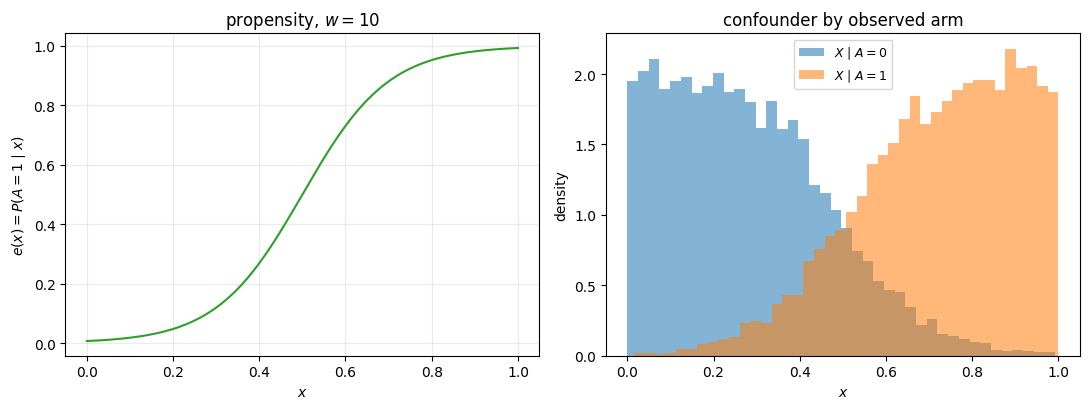

In [3]:
order = torch.argsort(X)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(X[order].cpu(), propensity[order].cpu(), color="tab:green")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel(r"$e(x) = P(A = 1 \mid x)$")
axes[0].set_title(f"propensity, $w = {W_CONF:.0f}$")
axes[0].grid(alpha=0.25)
for a, colour in ((0, "tab:blue"), (1, "tab:orange")):
    axes[1].hist(X[A == a].cpu().numpy(), bins=40, density=True, alpha=0.55,
                 color=colour, label=rf"$X \mid A = {a}$")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("density")
axes[1].set_title("confounder by observed arm")
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

## 3. Colour Law

$R/(R+B)$ recovers $X$, so the observed arms inherit the tilted confounder distributions while both
interventional laws are uniform. The recovery is verified numerically.

colour-ratio recovery of X: max |R/(R+B) - X| = 6.0e-08


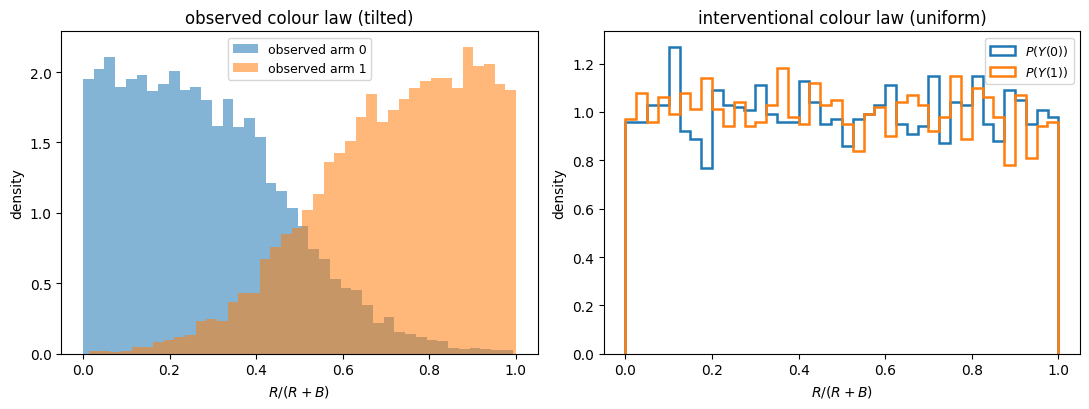

In [4]:
ratio_obs = {a: color_ratio(Y[A == a]).cpu().numpy() for a in (0, 1)}
ratio_int = {0: color_ratio(Y0).cpu().numpy(), 1: color_ratio(Y1).cpu().numpy()}

recovery_error = (color_ratio(Y) - X).abs().max().item()
print(f"colour-ratio recovery of X: max |R/(R+B) - X| = {recovery_error:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for a, colour in ((0, "tab:blue"), (1, "tab:orange")):
    axes[0].hist(ratio_obs[a], bins=40, density=True, alpha=0.55, color=colour,
                 label=f"observed arm {a}")
    axes[1].hist(ratio_int[a], bins=40, density=True, histtype="step", lw=1.8,
                 color=colour, label=f"$P(Y({a}))$")
for ax, title in zip(axes, ("observed colour law (tilted)", "interventional colour law (uniform)")):
    ax.set_xlabel("$R/(R+B)$")
    ax.set_ylabel("density")
    ax.set_title(title)
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 4. Overlap

Deterministic-intervention importance weights are $w_i^{(a)} = \mathbf 1\{a_i = a\} / e_a(x_i)$. At
$w = 10$ the propensity saturates near the colour extremes, so each arm's minority-colour tail
carries large weights.

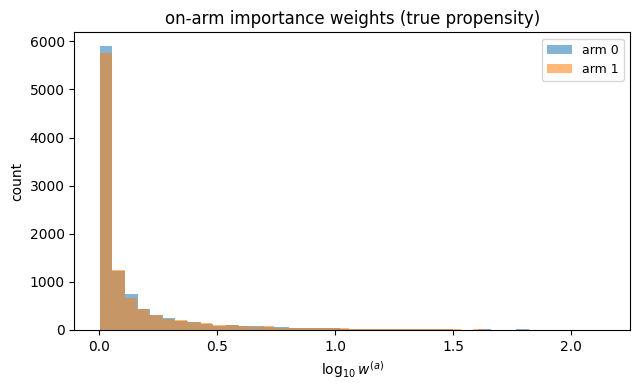

 arm    size      ESS   ESS / size   max weight
   0   10077   1174.0        0.117        138.5
   1    9923   1409.9        0.142        129.6


In [5]:
weights = {a: ((A == a).double() / (propensity if a == 1 else 1 - propensity).double()).cpu()
           for a in (0, 1)}
fig, ax = plt.subplots(figsize=(6.5, 4))
for a, colour in ((0, "tab:blue"), (1, "tab:orange")):
    on_arm = weights[a][(A == a).cpu()]
    ax.hist(np.log10(on_arm.numpy()), bins=40, alpha=0.55, color=colour, label=f"arm {a}")
ax.set_xlabel(r"$\log_{10} w^{(a)}$")
ax.set_ylabel("count")
ax.set_title("on-arm importance weights (true propensity)")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"{'arm':>4s} {'size':>7s} {'ESS':>8s} {'ESS / size':>12s} {'max weight':>12s}")
for a in (0, 1):
    on_arm = weights[a][(A == a).cpu()].numpy()
    ess = effective_sample_size(on_arm)
    print(f"{a:>4d} {len(on_arm):7d} {ess:8.1f} {ess / len(on_arm):12.3f} {on_arm.max():12.1f}")

## 5. Role of the Confounding Strength

$w$ controls both the colour shift each arm must undo (transport) and the overlap available to
estimate the target. The colour-law distance is the exact one-dimensional $W_1$ between the arm's
colour ratio and the uniform interventional one. Values are averaged over three seeds at
$n = 5000$.

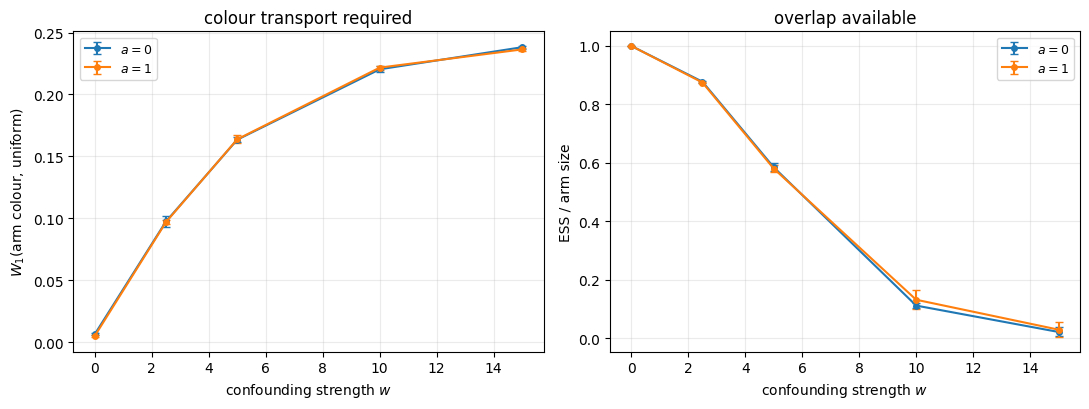

In [6]:
w_grid = [0.0, 2.5, 5.0, 10.0, 15.0]
seeds = range(3)
shift = {0: [], 1: []}
ess_fraction = {0: [], 1: []}
uniform_reference = torch.rand(5000, generator=torch.Generator().manual_seed(999))

for w in w_grid:
    per_seed = {0: ([], []), 1: ([], [])}
    for seed in seeds:
        g = torch.Generator(device=device).manual_seed(100 + seed)
        X_s, A_s, Y_s = sample_observed(pools, 5000, w_conf=w, tau=TAU, generator=g)
        e_s = torch.sigmoid(w * (X_s - 0.5))
        for a in (0, 1):
            ratio_arm = color_ratio(Y_s[A_s == a]).cpu()
            per_seed[a][0].append(sliced_wasserstein(ratio_arm[:, None],
                                                     uniform_reference[:, None],
                                                     n_projections=1, p=1, seed=0).item())
            on_arm = ((1.0 / (e_s if a == 1 else 1 - e_s))[A_s == a]).cpu().numpy()
            per_seed[a][1].append(effective_sample_size(on_arm) / len(on_arm))
    for a in (0, 1):
        shift[a].append(per_seed[a][0])
        ess_fraction[a].append(per_seed[a][1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for a, colour in ((0, "tab:blue"), (1, "tab:orange")):
    for ax, values, label in ((axes[0], shift[a], r"$W_1$(arm colour, uniform)"),
                              (axes[1], ess_fraction[a], "ESS / arm size")):
        values = np.array(values)
        ax.errorbar(w_grid, values.mean(axis=1), yerr=values.std(axis=1),
                    marker="o", ms=4, capsize=3, color=colour, label=f"$a = {a}$")
        ax.set_xlabel(r"confounding strength $w$")
        ax.set_ylabel(label)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9)
axes[0].set_title("colour transport required")
axes[1].set_title("overlap available")
fig.tight_layout()
plt.show()

## Summary

- Confounding is strong at the working point $w = 10$: the arms see complementary colour ranges
  ($\mathbb E[X \mid A=1] \approx 0.72$, $\mathbb E[X \mid A=0] \approx 0.28$), and each arm's
  minority-colour tail carries importance weights of order $10^2$.
- Both interventional laws share the uniform colour law but fix different digit classes, so
  deconfounding is entirely a **colour-transport** problem within a digit class — the scalar
  $R/(R+B)$ (which recovers $X$ to numerical precision) tracks it completely.
- The two arms are symmetric by construction; transport and overlap degrade together as $w$ grows.
  At the working point $w = 10$ the on-arm effective sample size is already down to $12$--$14\%$ of
  the arm, and by $w = 15$ it is a few percent.